# Turnover reduction

Stage 1 showed that costs eat most of the LightGBM signal: about 124x annual turnover at 6 bp. This notebook tests three ways to trade less, using the same out-of-sample scores:

- **Score smoothing**: rank scores per date, then take an exponential average over past dates (`smoothing_halflife`).
- **Holding buffer**: enter in the top/bottom 10%, stay until leaving the top/bottom `exit_fraction`.
- **Rebalance frequency**: every 5, 10 or 21 trading days.

**Protocol.** All 27 combinations are judged only on net Sharpe in the *tuning* period (2014-2018). The winner and the stage 1 configuration are then compared once on the *validation* period (2019 to 2024-10). The hold-out from 2024-11-01 stays untouched.

Run `uv run python research/stage1.py` and then `uv run python research/turnover.py` first.

In [1]:
import json
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

from quant_core.backtest import daily_returns
from quant_core.validation import ExperimentLog

ROOT = Path.cwd().parent if Path.cwd().name == 'research' else Path.cwd()
RESULTS = ROOT / 'data' / 'results'
TUNING_END = date(2018, 12, 31)
grid = pl.read_parquet(RESULTS / 'turnover_grid.parquet')
comparison = pl.read_parquet(RESULTS / 'turnover_comparison.parquet')
daily = pl.read_parquet(RESULTS / 'turnover_daily.parquet')
chosen = json.loads((RESULTS / 'turnover_chosen.json').read_text())
pl.Config.set_tbl_rows(30); pl.Config.set_float_precision(3); pl.Config.set_tbl_width_chars(140)
plt.rcParams['figure.figsize'] = (11, 4)

## Tuning grid (2014-2018, LightGBM)

Net Sharpe and annual turnover for every combination, best first.

In [2]:
grid

smoothing_halflife,exit_fraction,rebalance_every,net_sharpe,net_cagr,gross_sharpe,turnover
f64,f64,i64,f64,f64,f64,f64
10.000,0.300,5,0.472,0.043,0.547,12.640
0.000,0.200,10,0.422,0.038,0.717,49.364
0.000,0.300,21,0.415,0.036,0.552,21.771
0.000,null,21,0.400,0.034,0.629,35.709
10.000,0.200,5,0.370,0.033,0.482,18.874
10.000,0.300,10,0.357,0.031,0.424,11.285
0.000,0.200,21,0.338,0.028,0.507,27.057
3.000,0.300,5,0.316,0.027,0.485,27.917
3.000,0.300,10,0.298,0.025,0.437,22.789


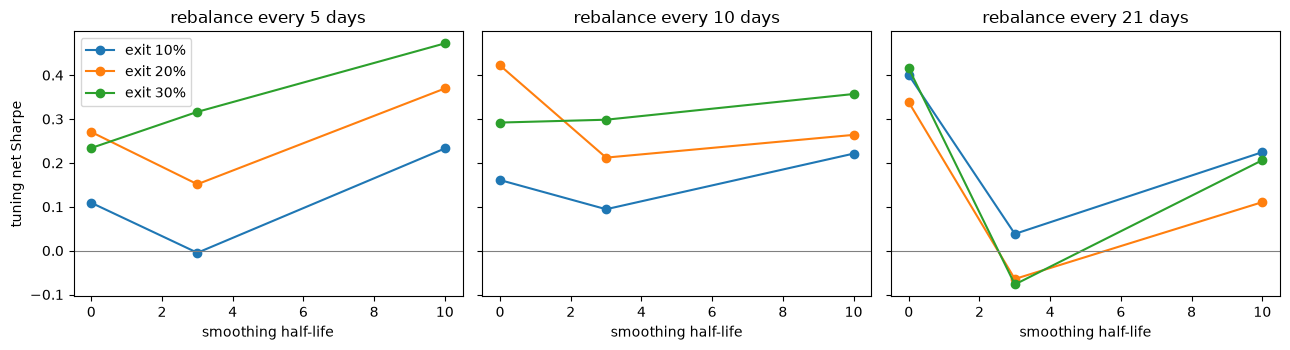

chosen: {'smoothing_halflife': 10.0, 'exit_fraction': 0.3, 'rebalance_every': 5}


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, k in zip(axes, (5, 10, 21)):
    g = grid.filter(pl.col('rebalance_every') == k).with_columns(pl.col('exit_fraction').fill_null(0.1))
    for exit_fraction in (0.1, 0.2, 0.3):
        s = g.filter(pl.col('exit_fraction') == exit_fraction).sort('smoothing_halflife')
        ax.plot(s['smoothing_halflife'], s['net_sharpe'], marker='o', label=f'exit {exit_fraction:.0%}')
    ax.set_title(f'rebalance every {k} days'); ax.set_xlabel('smoothing half-life'); ax.axhline(0, color='grey', lw=0.8)
axes[0].set_ylabel('tuning net Sharpe'); axes[0].legend(); plt.tight_layout(); plt.show()
print('chosen:', {k: chosen[k] for k in ('smoothing_halflife', 'exit_fraction', 'rebalance_every')})

## Validation (2019 to 2024-10): stage 1 configuration vs the chosen one

In [4]:
comparison.filter(pl.col('period') == 'validation').sort('model', 'config')

model,config,period,net_cagr,net_sharpe,gross_sharpe,max_drawdown,turnover
str,str,str,f64,f64,f64,f64,f64
"""combo""","""chosen""","""validation""",0.002,0.116,0.151,-0.454,12.479
"""combo""","""stage1""","""validation""",-0.086,-0.237,0.110,-0.506,143.255
"""lgbm""","""chosen""","""validation""",0.139,0.955,1.003,-0.250,11.611
"""lgbm""","""stage1""","""validation""",0.037,0.284,0.664,-0.319,124.766
"""ridge_lgbm""","""chosen""","""validation""",0.118,0.752,0.787,-0.267,9.524
"""ridge_lgbm""","""stage1""","""validation""",0.005,0.135,0.466,-0.403,127.480


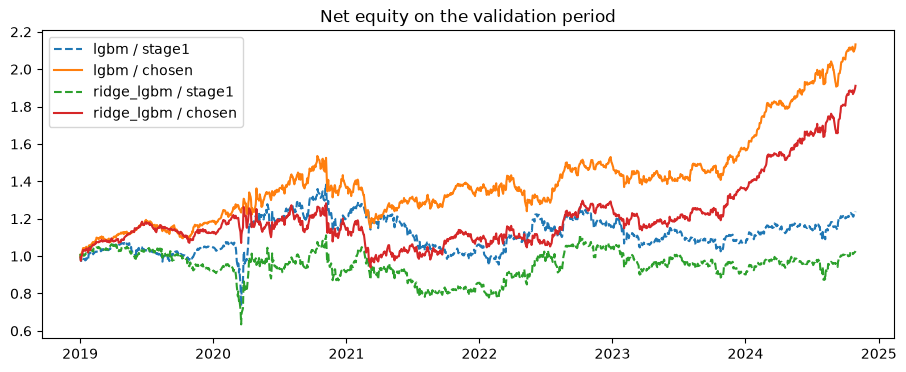

In [5]:
fig, ax = plt.subplots()
for (model, config), frame in daily.filter(pl.col('date') > TUNING_END).group_by('model', 'config', maintain_order=True):
    if model == 'combo':
        continue
    frame = frame.sort('date').with_columns(equity=(1 + pl.col('net')).cum_prod())
    ax.plot(frame['date'], frame['equity'], label=f'{model} / {config}', ls='-' if config == 'chosen' else '--')
ax.set_title('Net equity on the validation period'); ax.legend(); plt.show()

In [6]:
lgbm = daily.filter(pl.col('model') == 'lgbm')
(lgbm.group_by('config', year=pl.col('date').dt.year()).agg(net=(1 + pl.col('net')).product() - 1)
     .pivot('config', index='year', values='net').sort('year'))

year,chosen,stage1
i32,f64,f64
2014,0.020,0.015
2015,0.097,-0.024
2016,-0.113,-0.130
2017,0.156,0.060
2018,0.076,0.126
2019,0.189,0.046
2020,0.148,0.148
2021,-0.010,-0.115
2022,0.111,0.101


## Is it just a market bet?

A strategy that drifted into owning the market would look great in 2019-2024. Beta and correlation of net daily returns against SPY:

In [7]:
prices = pl.read_parquet(ROOT / 'data' / 'raw' / 'prices.parquet')
spy = daily_returns(prices.filter(pl.col('ticker') == 'SPY')).select('date', spy='ret')
d = daily.join(spy, on='date').with_columns(period=pl.when(pl.col('date') <= TUNING_END).then(pl.lit('tuning')).otherwise(pl.lit('validation')))
(d.group_by('model', 'config', 'period')
  .agg(beta=pl.cov('net', 'spy') / pl.col('spy').var(), corr=pl.corr('net', 'spy'))
  .sort('model', 'config', 'period'))

model,config,period,beta,corr
str,str,str,f64,f64
"""combo""","""chosen""","""tuning""",0.224,0.225
"""combo""","""chosen""","""validation""",-0.006,-0.005
"""combo""","""stage1""","""tuning""",0.245,0.235
"""combo""","""stage1""","""validation""",0.050,0.041
"""lgbm""","""chosen""","""tuning""",0.082,0.107
"""lgbm""","""chosen""","""validation""",0.156,0.211
"""lgbm""","""stage1""","""tuning""",0.130,0.180
"""lgbm""","""stage1""","""validation""",0.249,0.253
"""ridge_lgbm""","""chosen""","""tuning""",0.077,0.092


## Multiple testing

In [8]:
log = ExperimentLog(ROOT / 'research' / 'experiments.jsonl')
names = pl.Series('name', [e['name'].rsplit('/', 1)[0] for e in log.entries()])
print(f'{log.count()} evaluated variants recorded')
names.value_counts().sort('name')

36 evaluated variants recorded


name,count
str,u32
"""stage1""",6
"""turnover/tuning""",27
"""turnover/validation""",3


## Findings

Run of 2026-10-28 on the stage 1 out-of-sample scores.

1. **Trading less works.** Chosen on 2014-2018 alone: smoothing half-life 10 dates, holding buffer 30%,
   rebalance every 5 days. On the validation period (2019 to 2024-10) LightGBM turnover falls from about
   125x to 12x a year, and net Sharpe rises from 0.28 to 0.96 (net CAGR 3.7% to 13.9%).
2. **Costs almost vanish.** Gross and net Sharpe of the chosen configuration are close (1.00 vs 0.96),
   against 0.66 vs 0.28 for stage 1. The strategy now survives realistic costs instead of being decided by them.
3. **The improvement carries over.** The same configuration, never tuned on them, also lifts the Ridge +
   LightGBM ensemble (net Sharpe 0.14 to 0.75) and turns the combo baseline from losing to about flat.
4. **It is not a hidden market bet.** Beta to SPY stays small and drops slightly (0.25 to 0.16 on validation);
   both legs contribute, as before.
5. **Smoothing and the buffer work together.** Either alone helps less; slower rebalancing on top of them
   hurts, because the buffer already does that job while still reacting weekly.

### Caveats

- The chosen point sits at the edge of the grid (largest half-life, widest buffer). Even slower settings
  may be better, but extending the grid now would mean tuning with the validation period in view.
- In the tuning period smoothing lowered gross Sharpe (0.89 to 0.55); in validation it raised it
  (0.66 to 1.00). Part of the validation gain may be luck of the period, so the 0.96 is likely optimistic.
- Survivorship bias from stage 1 still applies. The experiment log now holds 36 variants.

### Next steps

- Freeze this configuration as the default for the app's backtest screen.
- Keep the hold-out untouched until the model side (sector-relative target, beta-neutral weights) is settled too.
